In [1]:
using Pkg; Pkg.activate("..")

using Dates
using Statistics
using Interpolations
using ForwardDiff
using NCDatasets
using PythonPlot
using JLD2

using PythonCall

# Py method interprets Array{Union{T,Missing}} as a
# numpy masked array.
# This allows for plotting with missing values.
function PythonCall.Py(a::Array{Union{T,Missing},N}) where {T,N}
    numpy_ma = pyimport("numpy").ma
    numpy_ma.array(coalesce.(a,zero(T)), mask=ismissing.(a))
end

plt = pyimport("matplotlib.pyplot")
cc = pyimport("metpy.plots")
units = pyimport("metpy.units").units
mpc = pyimport("metpy.calc")

# use a sans family font like Arial, Helvetica, Open Sans
rc("font", family="sans-serif")
rc("font"; Symbol("sans-serif") => ["Arial", "Helvetica", "Open Sans"])
fontsize = 16                      # used for labels and ticks in all plot cells
rc("font", size=fontsize)

# user-defined local modules:
include(abspath("sonde_profiles.jl"))
include("sonde_averaging.jl"); using .SondeAveraging

  Activating project at `~/projects/ASTRAL/soundings`


In [2]:
if !isdefined(Main, :profs)
    if !isfile("profs.jld2")
        # loads in ~1-2 min
        profs = all_profiles()[1]            # Revelle 2023, TGT 2024, IMD, Amini
        save("profs.jld2", "profs", profs)
    else
        # reloads in 12 s
        profs = load("profs.jld2")["profs"] 
    end
end


2292-element Vector{NamedTuple}:
 (source = "Revelle", station = "Revelle", time = DateTime("2023-06-17T00:00:00"), lat = 12.057, lon = 67.78558, p = [1008.4, 1007.3, 1006.2, 1005.0, 1003.9, 1002.8, 1001.6, 1000.5, 999.4, 998.3  …  44.5, 44.4, 44.3, 44.3, 44.2, 44.1, 44.1, 44.0, 43.9, 43.8], z = [20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0  …  21460.0, 21470.0, 21480.0, 21490.0, 21500.0, 21510.0, 21520.0, 21530.0, 21540.0, 21550.0], θ = [296.14212870865083, 299.5275505373331, 301.4178000442756, 301.3207614701387, 301.3150691203746, 301.40936724271654, 301.3124809200088, 301.30700918878205, 301.4016254601972, 301.39632711649705  …  514.9965131557885, 516.0570514679644, 516.8760807608036, 516.8760807608036, 517.2095742686615, 517.3003168716309, 517.5440390468355, 517.8794801361325, 518.215902615054, 518.3091141376722], rh = [43.0, 47.0, 52.0, 61.0, 71.0, 76.0, 76.0, 76.0, 76.0, 77.0  …  2.0, 3.0, 4.0, 1.0, 2.0, 2.0, 2.0, 3.0, 1.0, 3.0], u = [0.45532281931361135, 6.166035

In [5]:
# select sondes from `months` in/adjacent to the Arabian Sea (default: May, west of 77.57°E)
function select_may_arabian_sea(profs; months=(5,), lonrange=(-Inf, 77.57), latrange=(-Inf, Inf),
                                 imd_keep=("kochi", "mangalore", "minicoy", "santacruz"))   # coastal/island IMD stations
    return filter( p -> month(p.time) in months && (p.source != "IMD" || p.station in imd_keep) &&
        lonrange[1] <= p.lon <= lonrange[2] && 
        latrange[1] <= p.lat <= latrange[2],
        profs )
end

as = select_may_arabian_sea(profs)
println(length(as), " of ", length(profs), " soundings in May over AS.")

218 of 2292 soundings in May over AS.


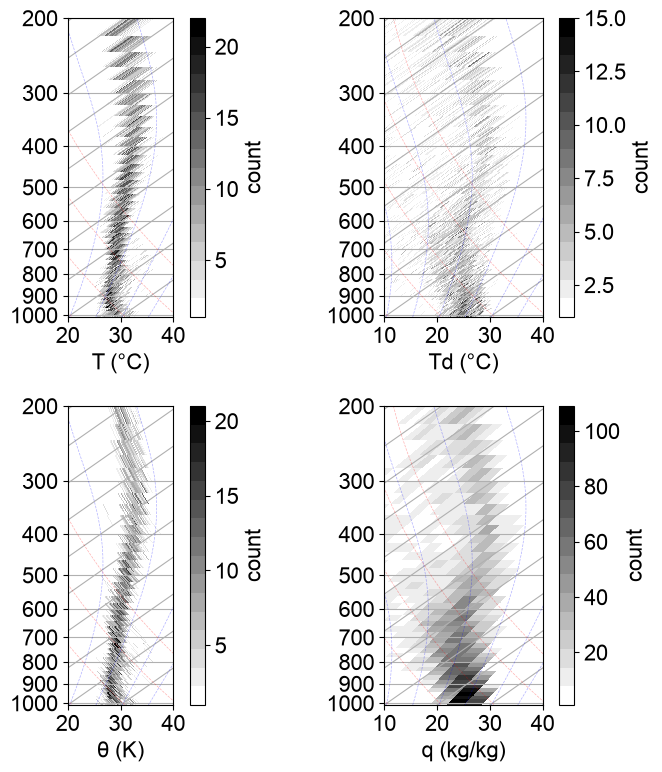

In [6]:
# histograms of T and Td (0.1 K), one realization per sounding, in 10 hPa bins, on skew-T log-p axes
pcenters=10.0:20.0:1020.0
halfwidth=10.0

hT = hist_field(as, :T; 
     dx=0.2, xlims=(-80.0, 40.0), pcenters=pcenters, halfwidth=halfwidth)
hTd = hist_field(as, :Td;
     dx=0.2, xlims=(-80.0, 40.0), pcenters=pcenters, halfwidth=halfwidth)
# q bins uniform in log q (about uniform in Td); linear bins put nearly all upper-air q in the lowest bin
qedges = 10 .^ range(-5, log10(0.03); length=41)      # 1e-5 to 3e-2 kg/kg
hq = hist_field(as, :q;
     edges=qedges, pcenters=pcenters, halfwidth=halfwidth)
hθ = hist_field(as, :θ; 
     dx=0.2, xlims=(280.0, 400.0), pcenters=pcenters, halfwidth=halfwidth)

ncolors = 16                          # number of discrete colors
cmap = get_cmap("gray_r", ncolors)

# the lowest pressure edge is 0 hPa (pcenters starts at 10, halfwidth 10): floor it so Td and log p stay finite
pedges = max.(hθ.pedges, 1.0)

# T edges for the θ histogram
# T [°C] at every (pressure edge, θ edge) corner: shape (np+1, nθ+1)
Tedge = hθ.xedges' .* (pedges ./ 1000) .^ κ .- 273.15
# Td edges for q histogram
# shape (np+1, nq+1) like Tedge; the q = 0 edge has no dewpoint, so floor it at qmin (a very cold Td)
qmin = 1e-6
Tdedge = [SondeAveraging.dewpoint(NaN, p; q=max(q, qmin)) for p in pedges, q in hq.xedges]
Pedge = pedges .* ones(1, length(hθ.xedges))   # same shape

plt.close("all")
fig = figure(figsize=(8, 8))
skewT  = cc.SkewT(fig; rotation=55, subplot=(2, 2, 1))
skewTd = cc.SkewT(fig; rotation=55, subplot=(2, 2, 2))
skewθ  = cc.SkewT(fig; rotation=55, subplot=(2, 2, 3))
skewq  = cc.SkewT(fig; rotation=55, subplot=(2, 2, 4))

function plotter(skew, h, Tedge, name)
     pe = max.(h.pedges, 1.0)
     # 2-D corner grids (θ, q panels) need a 2-D pressure grid of the same shape; 1-D edges (T, Td) do not
     P = Tedge isa AbstractMatrix ? pe .* ones(1, size(Tedge, 2)) : pe
     m = skew.ax.pcolormesh(Tedge, P, h.H'; cmap=cmap, vmin=1)   # h.H' is [level, bin], matching the edges
     skew.plot_dry_adiabats(alpha=0.3, linewidth=0.5)
     skew.plot_moist_adiabats(alpha=0.3, linewidth=0.5)
     skew.ax.set_ylim(1010, 200); skew.ax.set_xlim(20, 40)
     fig.colorbar(m; ax=skew.ax, label="count")
     skew.ax.set_xlabel(name; fontsize=fontsize)
     skew.ax.tick_params(axis="both"; labelsize=fontsize)   # xtick and ytick labels
end

plotter(skewθ, hθ, Tedge, "θ (K)")
plotter(skewT, hT, hT.xedges, "T (°C)")
plotter(skewTd, hTd, hTd.xedges, "Td (°C)")
plotter(skewq, hq, Tdedge, "q (kg/kg)")

skewTd.ax.set_xlim(10, 40)
skewq.ax.set_xlim(10, 40)

tight_layout()
gcf()

In [ ]:

for (skew, H, name) in zip((skewT, skewTd, skewθ), (hT, hTd, hθ), ("T [°C]", "Td [°C]", "θ [K]"))
    ax = skew.ax
    C = float.(H); C[C .== 0] .= NaN
    m = ax.pcolormesh(h.Tedges, h.pedges, collect(C'); cmap=cmap, vmin=1)
    skew.plot_dry_adiabats(alpha=0.3, linewidth=0.5)
    skew.plot_moist_adiabats(alpha=0.3, linewidth=0.5)
    ax.set_ylim(1010, 200)
    ax.set_xlabel(name; fontsize=fontsize)
    ax.tick_params(axis="both"; labelsize=fontsize)   # xtick and ytick labels
    # fig.colorbar(m; ax=ax, label="soundings")
end
skewT.ax.set_ylabel("p [hPa]"; fontsize=fontsize); skewTd.ax.set_ylabel("")

# set the x limits of each axis manually
skewT.ax.set_xlim(-10, 40)
skewTd.ax.set_xlim(-20, 30)
gcf()

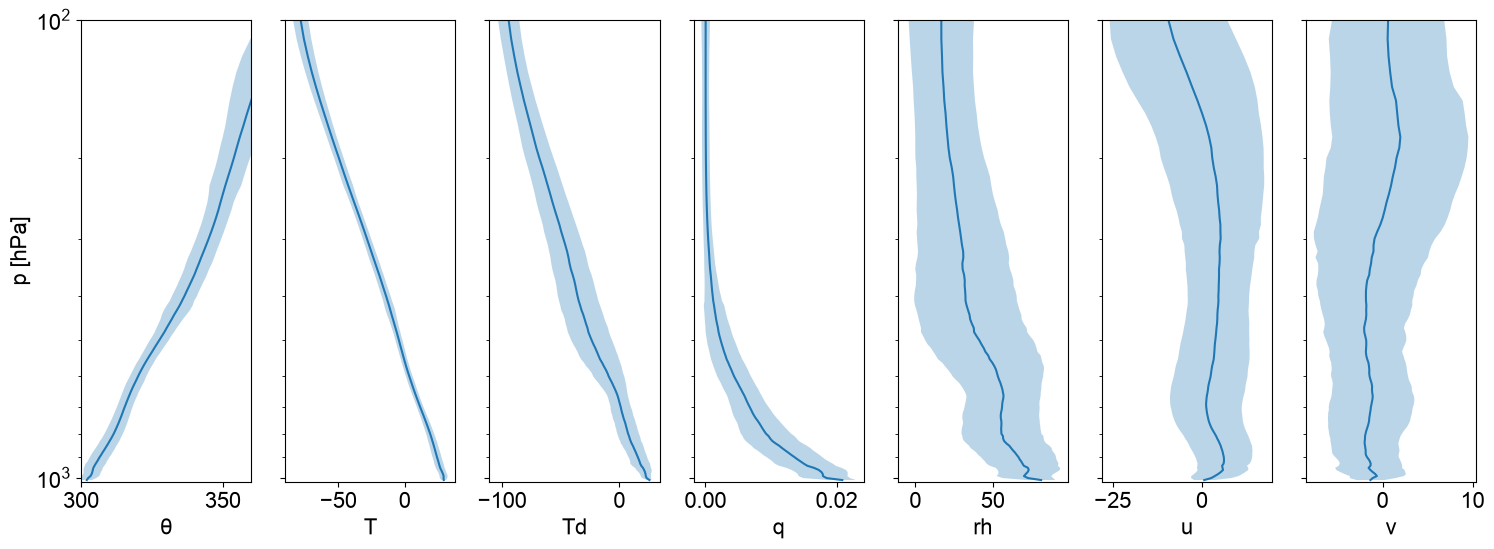

In [5]:
# mean on the 10 hPa grid: average higher-resolution, interpolate lower-resolution soundings
fields = (:θ, :T, :Td, :q, :rh, :u, :v)
ms = map(f -> SondeAveraging.mean_on_pgrid(as, f), fields)

plt.close("all")
fig, axs = subplots(1, length(fields); figsize=(18, 6), sharey=true)
for (ax, f, m) in zip(axs, fields, ms)
    pc = collect(m.pcenters)
    ax.fill_betweenx(pc, m.mean .- m.std, m.mean .+ m.std; alpha=0.3)
    ax.plot(m.mean, pc)
    ax.set_xlabel(string(f); fontsize=fontsize)
    ax.tick_params(axis="both"; labelsize=fontsize)
    ax.set_yscale("log")
end
axs[0].set_ylabel("p [hPa]"; fontsize=fontsize); axs[0].set_ylim(1020, 100)
axs[0].set_xlim(300, 360)
gcf()

236 soundings used, 197 rejected (too coarse or a layer not found)
surface  182.0 m
SCI base 1157.0 m
SCI top  1481.0 m
MML base 3796.0 m
MML top  5014.0 m
MI top   5540.0 m


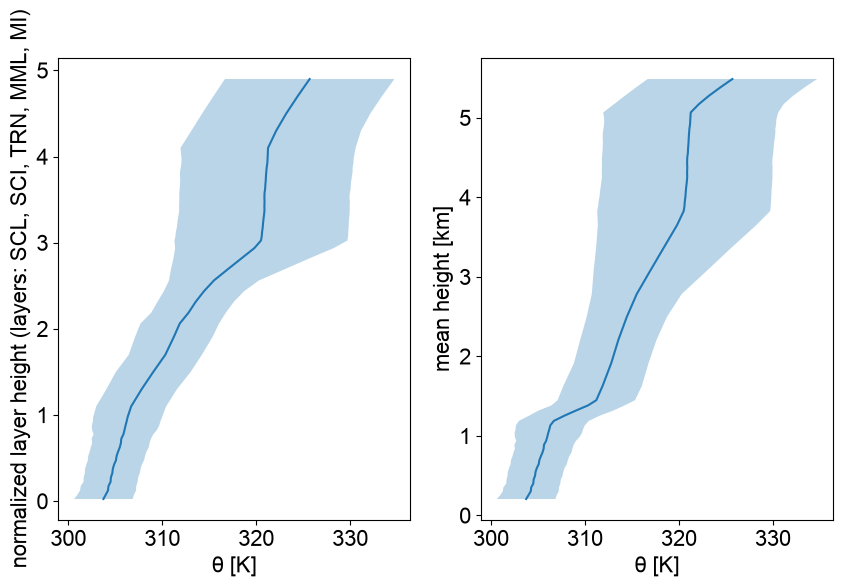

In [6]:
# composite in layers: shallow cumulus layer | SCI | transition | MML | MI (normalized height)
c = SondeAveraging.composite_layers(as, (:θ, :T, :Td, :q, :u, :v))
println(length(c.ok), " soundings used, ", c.nrejected, " rejected (too coarse or a layer not found)")
for (k, name) in enumerate(("surface", "SCI base", "SCI top", "MML base", "MML top", "MI top"))
    println(rpad(name, 9), round(mean(c.edges[:, k]); digits=0), " m")
end

plt.close("all")
fig, axs = subplots(1, 2; figsize=(10, 6))
axs[0].fill_betweenx(c.ζ, c.mean.θ .- c.std.θ, c.mean.θ .+ c.std.θ; alpha=0.3)
axs[0].plot(c.mean.θ, c.ζ)
axs[0].set_yticks(0:length(SondeAveraging.LAYERS)); axs[0].set_ylabel("normalized layer height (layers: $(join(SondeAveraging.LAYERS, ", ")))"; fontsize=fontsize)
axs[1].fill_betweenx(c.zmean ./ 1000, c.mean.θ .- c.std.θ, c.mean.θ .+ c.std.θ; alpha=0.3)
axs[1].plot(c.mean.θ, c.zmean ./ 1000)
axs[1].set_ylabel("mean height [km]"; fontsize=fontsize)
for ax in axs
    ax.set_xlabel("θ [K]"; fontsize=fontsize)
    ax.tick_params(axis="both"; labelsize=fontsize)
end
gcf()

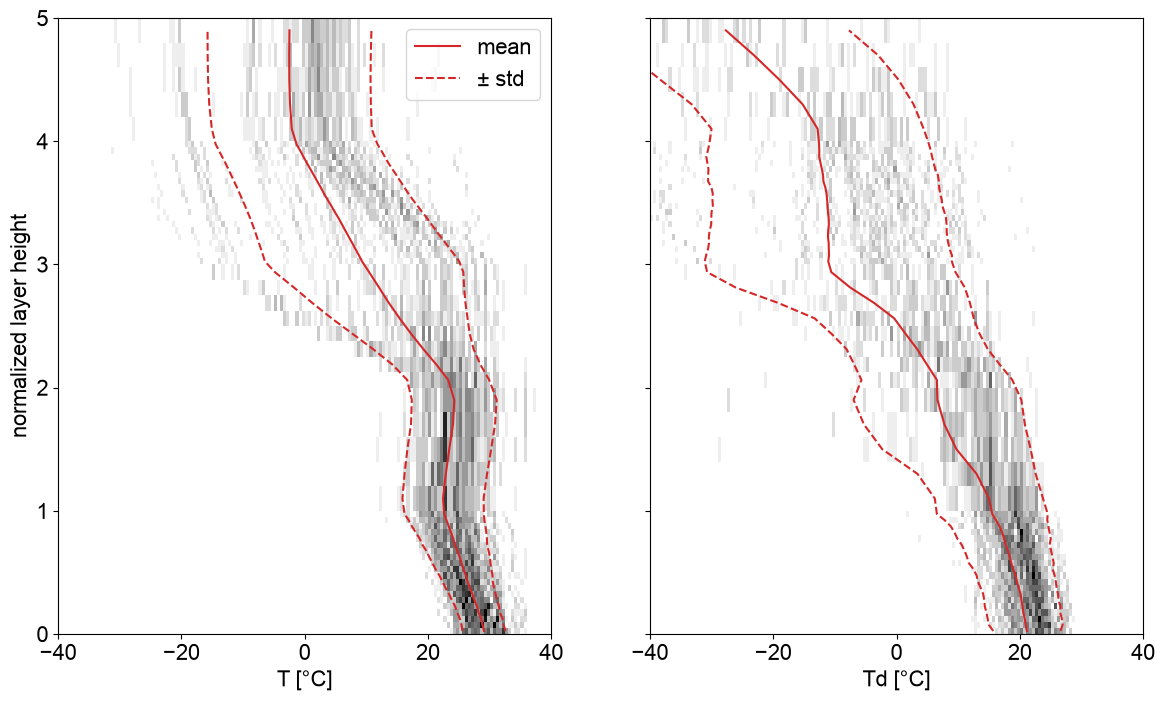

In [7]:
# histograms of T and Td in the composite (normalized) height bins, one realization per sounding
Tbin = 0.5                                   # bin width [K]
Tlims = (-80.0, 40.0)
nper = SondeAveraging.DEFAULT_NPER
# ζ edges of the composite levels: layer l spans l-1 to l, with nper[l] levels
ζedges = vcat([(l - 1) .+ (0:n-1) ./ n for (l, n) in enumerate(nper)]..., length(nper))

hc = map((:T, :Td)) do f
    H, Tedges = SondeAveraging.hist_pgrid(c.X[f]; dx=Tbin, xlims=Tlims)
    (H=H, Tedges=Tedges)
end

plt.close("all")
fig, axs = subplots(1, 2; figsize=(14, 8), sharey=true)
for (ax, f, h) in zip(axs, (:T, :Td), hc)
    C = float.(h.H); C[C .== 0] .= NaN
    m = ax.pcolormesh(h.Tedges, ζedges, collect(C'); cmap=cmap, vmin=1)
    ax.plot(c.mean[f], c.ζ; color="C3", label="mean")                       # mean ± std
    ax.plot(c.mean[f] .- c.std[f], c.ζ; color="C3", linestyle="--", label="± std")
    ax.plot(c.mean[f] .+ c.std[f], c.ζ; color="C3", linestyle="--")
    ax.set_xlim(-40, 40)
    ax.set_xlabel(string(f, " [°C]"); fontsize=fontsize)
    ax.set_yticks(0:length(nper))
    ax.tick_params(axis="both"; labelsize=fontsize)
end
axs[0].set_ylabel("normalized layer height"; fontsize=fontsize)
axs[0].legend(; fontsize=fontsize)
gcf()

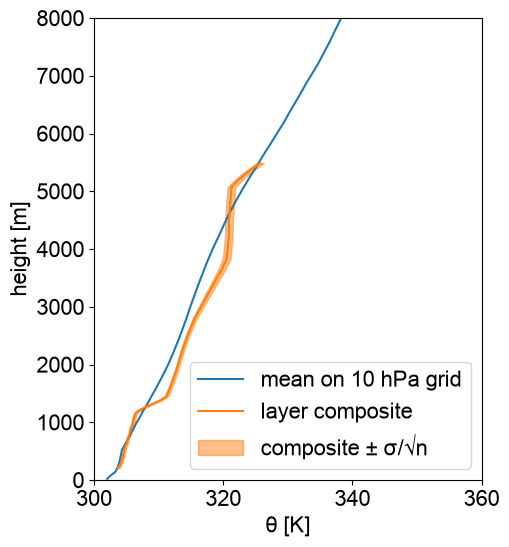

In [8]:
# compare mean θ from methods 2 and 3 against mean height
mz = SondeAveraging.mean_on_pgrid(as, :z)
mθ = ms[1]
plt.close("all")
fig, ax = subplots(figsize=(5, 6))
ax.plot(mθ.mean, mz.mean; label="mean on 10 hPa grid")
ax.plot(c.mean[:θ], c.zmean; label="layer composite")
# ax.plot(c.mean[:θ] .- c.std[:θ], c.zmean; linestyle="--", linewidth=1, label="layer composite -1σ")
# ax.plot(c.mean[:θ] .+ c.std[:θ], c.zmean; linestyle="--", linewidth=1, label="layer composite +1σ")
# standard deviation of the mean (standard error): σ/√n over the n soundings at each level
sem = c.std[:θ] ./ sqrt.(c.n[:θ])
ax.fill_betweenx(c.zmean, c.mean[:θ] .- sem, c.mean[:θ] .+ sem; color="C1", alpha=0.5, label="composite ± σ/√n")
ax.set_xlabel("θ [K]"; fontsize=fontsize); ax.set_ylabel("height [m]"; fontsize=fontsize)
ax.set_ylim(0, 8000); ax.legend(; fontsize=fontsize)
ax.set_xlim(300, 360)
ax.tick_params(axis="both"; labelsize=fontsize)
gcf()

In [9]:
# composite profile on a skew-T log-p diagram
cp = SondeAveraging.composite_layers(as, (:p, :T, :Td))     # mean p, T, Td at the composite levels
p, T, Td = cp.mean.p, cp.mean.T, cp.mean.Td

plt.close("all")
fig = figure(figsize=(8, 9))
skew = cc.SkewT(fig; rotation=45)
skew.plot(p, mpc.temperature_from_potential_temperature(p, mz.θ);
    color="C3", linewidth=2, label="T")
skew.plot(p, T; color="C3", linewidth=2, label="T")
skew.plot(p, Td; color="C0", linewidth=2, label="Td")
# standard deviation of the mean, σ/√n over the n soundings at each level
semT, semTd = cp.std.T ./ sqrt.(cp.n.T), cp.std.Td ./ sqrt.(cp.n.Td)
skew.ax.fill_betweenx(p, T .- semT, T .+ semT; color="C3", alpha=0.3, label="T ± σ/√n")
skew.ax.fill_betweenx(p, Td .- semTd, Td .+ semTd; color="C0", alpha=0.3, label="Td ± σ/√n")
skew.plot_dry_adiabats(alpha=0.3, linewidth=0.5)
skew.plot_moist_adiabats(alpha=0.3, linewidth=0.5)
skew.plot_mixing_lines(alpha=0.3, linewidth=0.5)
skew.ax.set_ylim(1010, 200); skew.ax.set_xlim(-40, 40)
skew.ax.set_xlabel("T, Td [°C]"; fontsize=fontsize); skew.ax.set_ylabel("p [hPa]"; fontsize=fontsize)
skew.ax.tick_params(axis="both"; labelsize=fontsize)
skew.ax.legend(; fontsize=fontsize)
gcf()

FieldError: FieldError: type NamedTuple has no field `θ`, available fields: `mean`, `std`, `n`, `X`, `pcenters`